# 14. Train calibration predictor with cached observability

This notebook keeps the calibration-prediction workflow of notebook 09, but replaces online Fisher/observability computation with the cached dimensionless soft-projector observability produced by notebook 11.

Caches are loaded from:

```text
tmp/observability_targets/train.pt
tmp/observability_targets/validation.pt
tmp/observability_targets/test.pt
```

Each physical calibration receives the cached 7D vector

\[
[\phi_x,\phi_y,\phi_z,\rho_x,\rho_y,\rho_z,\tau].
\]

The cached values are used in the same two places as observability was used in notebook 09:

1. as a 7D per-calibration feature appended to the corresponding measurement tokens;
2. in the observability-aware calibration correction loss.

For this first oracle/cached-observability experiment, sampling-rate augmentation and calibration events are disabled because they change the observability-target semantics. Frame randomization, calibration-prior perturbation, and measurement noise remain enabled.


## 1. Imports and repository root


In [1]:
from pathlib import Path
import inspect
import sys
import time
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

ROOT = Path.cwd()

for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader

from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SE3NoiseConfig, VectorNoiseConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.profiles import TransitionProfile

from obscalib.calibration.context import calibration_state_to_context
from obscalib.calibration.observability_targets import ObservabilityTargetCache
from obscalib.config import CalibrationHeadConfig, MLPConfig, ObsCalibModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import MeasurementType
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.obs_calib_model import ObsCalibModel
from obscalib.observability.structures import ObservabilityResult
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment parameters


In [2]:
##################################################
# Experiment
##################################################

CALIBRATION_LOSS_MODE = "observability_aware"  # "standard" or "observability_aware"
OBSERVABILITY_HOLD_WEIGHT = 1.0

OBSERVABILITY_SOURCE = "cached_dimensionless_soft_projector"
OBSERVABILITY_TOKEN_MODE = "per_calibration_7d"

RUN_NAME = f"kaist_calibration_cached_observability_{CALIBRATION_LOSS_MODE}_001"

RANDOM_SEED = 12345
TRAIN_AUGMENTATION_SEED = 23456
VALIDATION_AUGMENTATION_SEED = 34567
TEST_AUGMENTATION_SEED = 45678

##################################################
# Device
##################################################

DEVICE_NAME = "cuda"

if DEVICE_NAME == "auto":
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    DEVICE = torch.device(DEVICE_NAME)

MODEL_DTYPE = torch.float32

##################################################
# Dataset / windows
##################################################

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

##################################################
# DataLoader
##################################################

BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

##################################################
# Training
##################################################

NUM_EPOCHS = 100
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 200

##################################################
# Model
##################################################

MEASUREMENT_DIM = 6
BASE_TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2

D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
NUM_SUMMARY_TOKENS = 4
TRANSFORMER_DROPOUT = 0.1

MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
HEAD_HIDDEN_DIMS = (128, 64)
CALIBRATION_CONTEXT_DIM = 7

##################################################
# Cached observability
##################################################

CALIBRATION_KEYS = ("imu", "lidar")
OBSERVABILITY_CACHE_DIR = ROOT / "outputs" / "observability_targets"

OBSERVABILITY_TOKEN_FEATURE_DIM = 7
OBSERVABILITY_FEATURE_DIM = len(CALIBRATION_KEYS) * 7
TOKEN_INPUT_DIM = BASE_TOKEN_INPUT_DIM + OBSERVABILITY_TOKEN_FEATURE_DIM

OBSERVABILITY_PARAMETER_NAMES = (
    "phi_x",
    "phi_y",
    "phi_z",
    "rho_x",
    "rho_y",
    "rho_z",
    "tau",
)

##################################################
# Loss normalization
##################################################

ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TRANSLATION_LOSS_SCALE_M = 0.05
TIME_OFFSET_LOSS_SCALE_S = 0.015
CHANGE_TIME_LOSS_SCALE_S = WINDOW_DURATION_S

ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
CHANGE_EVENT_LOSS_WEIGHT = 0.1
CHANGE_TIME_LOSS_WEIGHT = 0.1

##################################################
# Scheduler
##################################################

LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 10

##################################################
# Resume
##################################################

RESUME_CHECKPOINT = None

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Observability source:", OBSERVABILITY_SOURCE)
print("Transformer token input dimension:", TOKEN_INPUT_DIM)


Device: cuda
Batch size: 16
Observability source: cached_dimensionless_soft_projector
Transformer token input dimension: 15


## 3. KAIST split, rig calibration, datasets, and loaders


In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")


##################################################
# Sequence-level split
##################################################

TRAIN_NAMES = [
    "Urban08",
    "Urban12",
    "Urban13",
    "Urban14",
    "Urban15",
    "Urban16",
]

VAL_NAMES = [
    "Urban26",
    "Urban28",
]

TEST_NAMES = [
    "Urban38",
    "Urban39",
]


ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
##################################################
# KAIST body-frame calibration
##################################################

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0,  0.0],
    [0.0, 0.0, 1.0,  1.7],
    [0.0, 0.0, 0.0,  1.0],
], dtype=float)

T_B_I = np.linalg.inv(T_I_B)


rig_calibration = KAISTRigCalibration(
    T_B_I=T_B_I,
    T_B_L=T_B_L,
    tau_imu_s=0.0,
    tau_lidar_s=0.0,
)


windowing_config = WindowingConfig(
    window_duration_s=WINDOW_DURATION_S,
    window_stride_s=WINDOW_STRIDE_S,
    max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR,
)


In [5]:
all_specs = build_kaist_sequence_specs(
    sequence_names=ALL_SEQUENCE_NAMES,
    kaist_dataset_root=KAIST_DATASET_ROOT,
    lidar_pose_root=LIDAR_POSE_ROOT,
)

spec_by_name = {
    spec.name: spec
    for spec in all_specs
}


train_dataset = KAISTCalibrationDataset(
    [spec_by_name[name] for name in TRAIN_NAMES],
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)

val_dataset = KAISTCalibrationDataset(
    [spec_by_name[name] for name in VAL_NAMES],
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)

test_dataset = KAISTCalibrationDataset(
    [spec_by_name[name] for name in TEST_NAMES],
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)


print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())


KAISTCalibrationDataset: 2005 windows from 6 sequences
approximate tensor storage: 37.4 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011
  Urban16: windows=780, duration=4458.2s, IMU=449215, LiDAR=37703

KAISTCalibrationDataset: 417 windows from 2 sequences
approximate tensor storage: 7.8 MiB
  Urban26: windows=94, duration=567.0s, IMU=58371, LiDAR=4553
  Urban28: windows=323, duration=1958.6s, IMU=197456, LiDAR=15651

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 13.1 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR=17005
  Urban39: windows=350, duration=1856.3s, IMU=186682, LiDAR=17195


In [6]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)


train_loader = make_kaist_dataloader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=DROP_LAST_TRAIN,
    num_workers=NUM_WORKERS,
    generator=train_shuffle_generator,
)

val_loader = make_kaist_dataloader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
)

test_loader = make_kaist_dataloader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
)


print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Synthetic calibration problem


In [7]:
USE_SAMPLING_RATE_AUGMENTATION = False
USE_CALIBRATION_EVENTS = False

augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(
        enabled=USE_SAMPLING_RATE_AUGMENTATION,
        minimum_imu_frequency_hz=40.0,
        minimum_lidar_frequency_hz=5.0,
        imu_probability=0.8,
        lidar_probability=0.5,
    ),

    frame_randomization=FrameRandomizationConfig(
        enabled=True,
    ),

    prior_perturbation=PriorPerturbationConfig(
        enabled=True,
        probability=0.8,
        rotation=PerturbationMagnitudeConfig(
            maximum=np.deg2rad(15.0),
        ),
        translation=PerturbationMagnitudeConfig(
            maximum=0.15,
        ),
        time_offset=PerturbationMagnitudeConfig(
            maximum=0.03,
        ),
    ),

    calibration_event=CalibrationEventConfig(
        enabled=USE_CALIBRATION_EVENTS,
        event_probability=0.5,
        rotation_probability=0.8,
        translation_probability=0.7,
        time_offset_probability=0.5,
        rotation=PerturbationMagnitudeConfig(
            maximum=np.deg2rad(10.0),
        ),
        translation=PerturbationMagnitudeConfig(
            maximum=0.10,
        ),
        time_offset=PerturbationMagnitudeConfig(
            maximum=0.0095,
        ),
        profile_weights={
            TransitionProfile.STEP: 1.0,
            TransitionProfile.LINEAR: 1.0,
            TransitionProfile.SMOOTHSTEP: 1.0,
        },
        minimum_transition_duration_s=0.5,
        maximum_transition_duration_s=3.0,
        minimum_pre_event_fraction=0.2,
        minimum_post_event_fraction=0.2,
    ),

    noise=NoiseAugmentationConfig(
        enabled=True,
        vector_by_type={
            MeasurementType.IMU_GYROSCOPE: VectorNoiseConfig(
                gaussian_std=0.01,
                window_bias_std=0.003,
            ),
            MeasurementType.IMU_ACCELEROMETER: VectorNoiseConfig(
                gaussian_std=0.08,
                window_bias_std=0.03,
            ),
        },
        se3_by_type={
            MeasurementType.LIDAR_POSE: SE3NoiseConfig(
                rotation_std=np.deg2rad(0.15),
                translation_std=0.01,
            ),
        },
    ),
)

if augmentation_config.sampling_rate.enabled:
    raise ValueError(
        "This first cached-observability experiment requires sampling-rate augmentation OFF."
    )

if augmentation_config.calibration_event.enabled:
    raise ValueError(
        "This first cached-observability experiment requires calibration events OFF."
    )

augmentation_pipeline = AugmentationPipeline(
    augmentation_config
)

print("sampling-rate augmentation:", augmentation_config.sampling_rate.enabled)
print("frame randomization:", augmentation_config.frame_randomization.enabled)
print("prior perturbation:", augmentation_config.prior_perturbation.enabled)
print("calibration events:", augmentation_config.calibration_event.enabled)
print("measurement noise:", augmentation_config.noise.enabled)


sampling-rate augmentation: False
frame randomization: True
prior perturbation: True
calibration events: False
measurement noise: True


## 5. Load cached observability


In [8]:
def load_cached_observability(dataset, *, split_name):
    cache_path = OBSERVABILITY_CACHE_DIR / f"{split_name}.pt"

    if not cache_path.exists():
        raise FileNotFoundError(
            f"Missing cached observability file {cache_path}. "
            "Run notebook 11 target-cache construction first."
        )

    saved = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=True,
    )

    if not isinstance(saved, dict):
        raise TypeError(
            f"Expected dictionary in {cache_path}, got {type(saved).__name__}."
        )

    if "values" not in saved or "calibration_keys" not in saved:
        raise KeyError(
            f"Cache {cache_path} must contain 'values' and 'calibration_keys'."
        )

    calibration_keys = tuple(saved["calibration_keys"])

    if calibration_keys != CALIBRATION_KEYS:
        raise ValueError(
            f"Cache {cache_path} has calibration keys {calibration_keys}, "
            f"expected {CALIBRATION_KEYS}."
        )

    values = saved["values"].detach().to(
        device="cpu",
        dtype=torch.float32,
    )

    expected_shape = (
        len(dataset),
        len(CALIBRATION_KEYS),
        7,
    )

    if tuple(values.shape) != expected_shape:
        raise ValueError(
            f"Cache {cache_path} has shape {tuple(values.shape)}, "
            f"expected {expected_shape}."
        )

    if not torch.isfinite(values).all():
        raise ValueError(
            f"Cache {cache_path} contains non-finite values."
        )

    if torch.any(values < 0.0) or torch.any(values > 1.0):
        raise ValueError(
            f"Cache {cache_path} contains values outside [0, 1]."
        )

    metadata = saved.get("metadata", {})

    if metadata:
        cached_window_duration_s = metadata.get("window_duration_s")
        cached_window_stride_s = metadata.get("window_stride_s")

        if cached_window_duration_s is not None and float(cached_window_duration_s) != float(WINDOW_DURATION_S):
            raise ValueError(
                f"Cache window_duration_s={cached_window_duration_s}, "
                f"but notebook uses {WINDOW_DURATION_S}."
            )

        if cached_window_stride_s is not None and float(cached_window_stride_s) != float(WINDOW_STRIDE_S):
            raise ValueError(
                f"Cache window_stride_s={cached_window_stride_s}, "
                f"but notebook uses {WINDOW_STRIDE_S}."
            )

    cache = ObservabilityTargetCache(
        values=values,
        calibration_keys=calibration_keys,
    )

    print(
        f"Loaded {split_name:10s} cache {tuple(values.shape)} from {cache_path}"
    )

    return cache


train_observability_cache = load_cached_observability(
    train_dataset,
    split_name="train",
)

val_observability_cache = load_cached_observability(
    val_dataset,
    split_name="validation",
)

test_observability_cache = load_cached_observability(
    test_dataset,
    split_name="test",
)


Loaded train      cache (2005, 2, 7) from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/train.pt
Loaded validation cache (417, 2, 7) from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/validation.pt
Loaded test       cache (699, 2, 7) from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/test.pt


In [9]:
print("=" * 92)
print("CACHED TRAIN OBSERVABILITY")
print("=" * 92)

for calibration_index, calibration_key in enumerate(CALIBRATION_KEYS):
    print()
    print(calibration_key)

    values = train_observability_cache.values[
        :,
        calibration_index,
        :,
    ]

    for parameter_index, parameter_name in enumerate(OBSERVABILITY_PARAMETER_NAMES):
        coordinate = values[:, parameter_index]

        print(
            f"{parameter_name:6s}  "
            f"mean={float(coordinate.mean()):.6f}  "
            f"std={float(coordinate.std()):.6f}  "
            f"min={float(coordinate.min()):.6f}  "
            f"max={float(coordinate.max()):.6f}"
        )


CACHED TRAIN OBSERVABILITY

imu
phi_x   mean=0.198379  std=0.144936  min=0.000874  max=0.496882
phi_y   mean=0.207841  std=0.137368  min=0.001488  max=0.496207
phi_z   mean=0.143697  std=0.111289  min=0.000457  max=0.466196
rho_x   mean=0.000000  std=0.000000  min=0.000000  max=0.000000
rho_y   mean=0.000000  std=0.000000  min=0.000000  max=0.000000
rho_z   mean=0.000000  std=0.000000  min=0.000000  max=0.000000
tau     mean=0.624156  std=0.281503  min=0.009344  max=0.990304

lidar
phi_x   mean=0.198379  std=0.144936  min=0.000874  max=0.496881
phi_y   mean=0.207841  std=0.137368  min=0.001488  max=0.496207
phi_z   mean=0.143698  std=0.111289  min=0.000457  max=0.466196
rho_x   mean=0.000000  std=0.000000  min=0.000000  max=0.000000
rho_y   mean=0.000000  std=0.000000  min=0.000000  max=0.000000
rho_z   mean=0.000000  std=0.000000  min=0.000000  max=0.000000
tau     mean=0.500930  std=0.247624  min=0.014361  max=0.989432


## 6. Model and cached-observability forward path


In [10]:
model_config = ObsCalibModelConfig(
    transformer=TransformerConfig(
        input_dim=TOKEN_INPUT_DIM,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        num_layers=NUM_TRANSFORMER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=TRANSFORMER_DROPOUT,
        activation="gelu",
        num_summary_tokens=NUM_SUMMARY_TOKENS,
    ),

    mlp=MLPConfig(
        hidden_dims=MLP_HIDDEN_DIMS,
        output_dim=SHARED_FEATURE_DIM,
        activation="gelu",
        dropout=0.1,
    ),

    calibration_head=CalibrationHeadConfig(
        calibration_context_dim=CALIBRATION_CONTEXT_DIM,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=0.1,
    ),

    head_keys=CALIBRATION_KEYS,
)

model = ObsCalibModel(
    model_config
).to(
    device=DEVICE,
    dtype=MODEL_DTYPE,
)

geometry_processor = GeometryProcessor()

tokenizer = Tokenizer(
    measurement_dim=MEASUREMENT_DIM,
    calibration_keys=CALIBRATION_KEYS,
)


def cached_observability_for_indices(cache, dataset_indices, *, device, dtype):
    calibration_features = cache.targets_for_indices(
        dataset_indices,
        device=device,
        dtype=dtype,
    )

    for calibration_key in CALIBRATION_KEYS:
        if calibration_key not in calibration_features:
            raise KeyError(
                f"Cached observability is missing calibration key {calibration_key!r}."
            )

        values = calibration_features[calibration_key]

        if values.ndim != 2 or values.shape[-1] != 7:
            raise ValueError(
                f"Cached observability for {calibration_key!r} must have shape [B, 7], "
                f"got {tuple(values.shape)}."
            )

        if not torch.isfinite(values).all():
            raise ValueError(
                f"Cached observability for {calibration_key!r} contains non-finite values."
            )

        if torch.any(values < 0.0) or torch.any(values > 1.0):
            raise ValueError(
                f"Cached observability for {calibration_key!r} must lie in [0, 1]."
            )

    global_features = torch.cat(
        [
            calibration_features[calibration_key]
            for calibration_key in CALIBRATION_KEYS
        ],
        dim=-1,
    )

    result_signature = inspect.signature(ObservabilityResult)

    if "calibration_features" in result_signature.parameters:
        return ObservabilityResult(
            raw=None,
            features=global_features,
            calibration_features=calibration_features,
        )

    result = ObservabilityResult(
        raw=None,
        features=global_features,
    )

    try:
        result.calibration_features = calibration_features
        return result
    except Exception:
        return SimpleNamespace(
            raw=None,
            features=global_features,
            calibration_features=calibration_features,
        )


def forward_cached_calibration_model(window, observability):
    canonical_streams = geometry_processor(
        window.streams,
        window.metadata,
        window.current_calibration,
    )

    ##################################################
    # Build ordinary measurement tokens first
    #
    # Do not pass observability here because the current
    # Tokenizer would append the complete global 14D vector
    # to every token.
    ##################################################

    tokens = tokenizer(
        canonical_streams,
        observability=None,
    )

    if tokens.calibration_ids is None:
        raise RuntimeError(
            "Tokenizer must emit calibration_ids for calibration-local observability."
        )

    if tokens.x.shape[-1] != BASE_TOKEN_INPUT_DIM:
        raise RuntimeError(
            f"Base tokenizer produced token dimension {tokens.x.shape[-1]}, "
            f"expected {BASE_TOKEN_INPUT_DIM}."
        )

    ##################################################
    # Append the 7D observability vector belonging to
    # each token's physical calibration.
    #
    # calibration_ids follow CALIBRATION_KEYS order:
    #     0 -> imu
    #     1 -> lidar
    ##################################################

    token_observability = torch.zeros(
        (
            tokens.x.shape[0],
            tokens.x.shape[1],
            OBSERVABILITY_TOKEN_FEATURE_DIM,
        ),
        dtype=tokens.x.dtype,
        device=tokens.x.device,
    )

    for calibration_id, calibration_key in enumerate(CALIBRATION_KEYS):
        calibration_observability = observability.calibration_features[
            calibration_key
        ].to(
            device=tokens.x.device,
            dtype=tokens.x.dtype,
        )

        if calibration_observability.shape != (
            tokens.x.shape[0],
            OBSERVABILITY_TOKEN_FEATURE_DIM,
        ):
            raise ValueError(
                f"Observability for {calibration_key!r} must have shape "
                f"[B, {OBSERVABILITY_TOKEN_FEATURE_DIM}], got "
                f"{tuple(calibration_observability.shape)}."
            )

        calibration_mask = (
            tokens.calibration_ids
            == calibration_id
        )

        token_observability = torch.where(
            calibration_mask.unsqueeze(-1),
            calibration_observability[:, None, :],
            token_observability,
        )

    tokens.x = torch.cat(
        [
            tokens.x,
            token_observability,
        ],
        dim=-1,
    )

    if tokens.x.shape[-1] != TOKEN_INPUT_DIM:
        raise RuntimeError(
            f"Final token dimension is {tokens.x.shape[-1]}, "
            f"expected {TOKEN_INPUT_DIM}."
        )

    ##################################################
    # Calibration-head context
    ##################################################

    calibration_context = {
        calibration_key: calibration_state_to_context(
            window.current_calibration[
                calibration_key
            ]
        )
        for calibration_key in model_config.head_keys
    }

    model_output = model(
        tokens,
        calibration_context,
    )

    return SimpleNamespace(
        model_output=model_output,
        tokens=tokens,
        observability=observability,
    )

num_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

num_trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Parameters:", num_parameters)
print("Trainable parameters:", num_trainable_parameters)


Parameters: 2615058
Trainable parameters: 2615058


## 7. Experiment snapshot and optimizer


In [11]:
EXPERIMENT_SNAPSHOT = {
    "schema_version": 2,

    "observability_config": {
        "source": OBSERVABILITY_SOURCE,
        "cache_directory": str(OBSERVABILITY_CACHE_DIR),
        "calibration_keys": tuple(CALIBRATION_KEYS),
        "coordinate_order": tuple(OBSERVABILITY_PARAMETER_NAMES),
        "feature_dim": OBSERVABILITY_FEATURE_DIM,
        "token_feature_mode": OBSERVABILITY_TOKEN_MODE,
        "token_feature_dim": OBSERVABILITY_TOKEN_FEATURE_DIM,
    },

    "model_config": model_config,
    "measurement_dim": MEASUREMENT_DIM,
    "windowing_config": windowing_config,
    "rig_calibration": rig_calibration,
    "augmentation_config": augmentation_config,

    "loss_config": {
        "calibration_loss_mode": CALIBRATION_LOSS_MODE,
        "observability_hold_weight": OBSERVABILITY_HOLD_WEIGHT,
        "rotation_loss_scale_rad": ROTATION_LOSS_SCALE_RAD,
        "translation_loss_scale_m": TRANSLATION_LOSS_SCALE_M,
        "time_offset_loss_scale_s": TIME_OFFSET_LOSS_SCALE_S,
        "change_time_loss_scale_s": CHANGE_TIME_LOSS_SCALE_S,
        "rotation_loss_weight": ROTATION_LOSS_WEIGHT,
        "translation_loss_weight": TRANSLATION_LOSS_WEIGHT,
        "time_offset_loss_weight": TIME_OFFSET_LOSS_WEIGHT,
        "change_event_loss_weight": CHANGE_EVENT_LOSS_WEIGHT,
        "change_time_loss_weight": CHANGE_TIME_LOSS_WEIGHT,
    },

    "sequence_split": {
        "train": tuple(TRAIN_NAMES),
        "validation": tuple(VAL_NAMES),
        "test": tuple(TEST_NAMES),
    },

    "training_config": {
        "run_name": RUN_NAME,
        "model_dtype": str(MODEL_DTYPE),
        "random_seed": RANDOM_SEED,
        "train_augmentation_seed": TRAIN_AUGMENTATION_SEED,
        "validation_augmentation_seed": VALIDATION_AUGMENTATION_SEED,
        "test_augmentation_seed": TEST_AUGMENTATION_SEED,
    },
}


In [12]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)


scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=LR_REDUCTION_FACTOR,
    patience=LR_PATIENCE_EPOCHS,
)


## 8. Calibration loss


In [13]:
def _observability_aware_correction_loss(prediction, target, observability, scale):
    """Train observable coordinates toward the full correction and strongly center unobservable coordinates at zero."""

    prediction_scaled = prediction / scale
    target_scaled = target / scale

    target_loss = F.smooth_l1_loss(prediction_scaled, target_scaled, reduction="none")
    hold_loss = torch.abs(prediction_scaled)

    target_weight = observability
    hold_weight = OBSERVABILITY_HOLD_WEIGHT * torch.square(1.0 - observability)

    weighted_loss = target_weight * target_loss + hold_weight * hold_loss

    return weighted_loss.mean()


def compute_training_loss(window, model_output, observability=None):
    """Compute normalized calibration and auxiliary losses for all model heads with selectable standard or observability-aware correction losses."""

    if window.targets is None:
        raise ValueError("Training window has no targets.")

    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_heads = 0

    for calibration_key, prediction in model_output.predictions.items():
        if calibration_key not in window.targets:
            raise KeyError(f"Missing training target for calibration head {calibration_key!r}.")

        target = window.targets[calibration_key]
        current_state = window.current_calibration[calibration_key]

        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Calibration target {calibration_key!r} does not contain final calibration state.")

        ##################################################
        # Geometric correction target
        ##################################################
        target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
        target_delta_xi = se3_log(target_delta_transform)
        target_delta_tau = target.next_time_offset - current_state.time_offset

        ##################################################
        # Primary calibration losses
        ##################################################
        if CALIBRATION_LOSS_MODE == "standard":
            rotation_loss = F.smooth_l1_loss(prediction.delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD, target_delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD)
            translation_loss = F.smooth_l1_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
            time_offset_loss = F.smooth_l1_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_delta_tau / TIME_OFFSET_LOSS_SCALE_S)
        elif CALIBRATION_LOSS_MODE == "observability_aware":
            if observability is None:
                raise ValueError("Observability-aware loss requires an ObservabilityResult.")
            if observability.calibration_features is None:
                raise ValueError("Observability-aware loss requires calibration-local observability features.")
            if calibration_key not in observability.calibration_features:
                raise KeyError(f"Observability features are missing calibration key {calibration_key!r}.")

            calibration_observability = observability.calibration_features[calibration_key]

            if calibration_observability.shape != (prediction.delta_xi.shape[0], 7):
                raise ValueError(f"Observability features for calibration key {calibration_key!r} must have shape [B, 7], got {tuple(calibration_observability.shape)}.")

            calibration_observability = calibration_observability.detach().to(device=prediction.delta_xi.device, dtype=prediction.delta_xi.dtype)

            if not torch.isfinite(calibration_observability).all():
                raise ValueError(f"Observability features for calibration key {calibration_key!r} contain non-finite values.")

            if torch.any(calibration_observability < 0.0) or torch.any(calibration_observability > 1.0):
                raise ValueError(f"Observability features for calibration key {calibration_key!r} must lie in [0, 1].")

            observability_phi = calibration_observability[:, :3]
            observability_rho = calibration_observability[:, 3:6]
            observability_tau = calibration_observability[:, 6:7]

            rotation_loss = _observability_aware_correction_loss(prediction.delta_xi[:, :3], target_delta_xi[:, :3], observability_phi, ROTATION_LOSS_SCALE_RAD)
            translation_loss = _observability_aware_correction_loss(prediction.delta_xi[:, 3:], target_delta_xi[:, 3:], observability_rho, TRANSLATION_LOSS_SCALE_M)
            time_offset_loss = _observability_aware_correction_loss(prediction.delta_tau, target_delta_tau, observability_tau, TIME_OFFSET_LOSS_SCALE_S)

            metrics[f"{calibration_key}/observability_phi_mean"] = observability_phi.mean().detach().item()
            metrics[f"{calibration_key}/observability_rho_mean"] = observability_rho.mean().detach().item()
            metrics[f"{calibration_key}/observability_tau_mean"] = observability_tau.mean().detach().item()
        else:
            raise ValueError(f"Unknown CALIBRATION_LOSS_MODE={CALIBRATION_LOSS_MODE!r}.")

        ##################################################
        # Auxiliary event losses
        ##################################################
        if target.change_label is None:
            change_event_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
            change_time_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
            change_labels = None
        else:
            change_labels = target.change_label.to(dtype=prediction.change_event_logit.dtype)
            change_event_loss = F.binary_cross_entropy_with_logits(prediction.change_event_logit, change_labels)

            positive_event_mask = change_labels[:, 0] > 0.5

            if target.change_time is not None and torch.any(positive_event_mask):
                change_time_loss = F.smooth_l1_loss(prediction.change_time[positive_event_mask] / CHANGE_TIME_LOSS_SCALE_S, target.change_time[positive_event_mask] / CHANGE_TIME_LOSS_SCALE_S)
            else:
                change_time_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)

        ##################################################
        # Head loss
        ##################################################
        head_loss = ROTATION_LOSS_WEIGHT * rotation_loss + TRANSLATION_LOSS_WEIGHT * translation_loss + TIME_OFFSET_LOSS_WEIGHT * time_offset_loss + CHANGE_EVENT_LOSS_WEIGHT * change_event_loss + CHANGE_TIME_LOSS_WEIGHT * change_time_loss
        total_loss = total_loss + head_loss
        num_heads += 1

        ##################################################
        # Human-readable metrics
        ##################################################
        rotation_error_rad = torch.linalg.vector_norm(prediction.delta_xi[:, :3] - target_delta_xi[:, :3], dim=-1)
        translation_error_m = torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_delta_xi[:, 3:], dim=-1)
        time_offset_error_s = torch.abs(prediction.delta_tau[:, 0] - target_delta_tau[:, 0])

        metrics[f"{calibration_key}/rotation_error_deg"] = torch.rad2deg(rotation_error_rad).mean().detach().item()
        metrics[f"{calibration_key}/translation_error_cm"] = (100.0 * translation_error_m).mean().detach().item()
        metrics[f"{calibration_key}/time_offset_error_ms"] = (1000.0 * time_offset_error_s).mean().detach().item()
        metrics[f"{calibration_key}/loss_rotation"] = rotation_loss.detach().item()
        metrics[f"{calibration_key}/loss_translation"] = translation_loss.detach().item()
        metrics[f"{calibration_key}/loss_time_offset"] = time_offset_loss.detach().item()
        metrics[f"{calibration_key}/loss_change_event"] = change_event_loss.detach().item()
        metrics[f"{calibration_key}/loss_change_time"] = change_time_loss.detach().item()

        if change_labels is not None:
            predicted_labels = torch.sigmoid(prediction.change_event_logit[:, 0]) >= 0.5
            true_labels = change_labels[:, 0] >= 0.5
            metrics[f"{calibration_key}/event_accuracy"] = (predicted_labels == true_labels).float().mean().detach().item()

            if target.change_time is not None and torch.any(true_labels):
                metrics[f"{calibration_key}/change_time_error_s"] = (prediction.change_time[true_labels, 0] - target.change_time[true_labels, 0]).mean().detach().item()

    if num_heads == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_loss = total_loss / num_heads
    metrics["loss_total"] = total_loss.detach().item()

    return total_loss, metrics


## 9. Training helpers


In [14]:
def make_augmentation_generator(seed: int):
    """Create a generator on the same device used by augmentation tensors."""

    return torch.Generator(
        device=DEVICE.type
    ).manual_seed(
        seed
    )


def accumulate_metrics(metric_sums: dict[str, float], metrics: dict[str, float], batch_size: int):
    for key, value in metrics.items():
        metric_sums[key] = (
            metric_sums.get(key, 0.0)
            + float(value) * batch_size
        )


def normalize_metrics(metric_sums: dict[str, float], num_samples: int):
    return {
        key: value / num_samples
        for key, value in metric_sums.items()
    }


In [15]:
def run_epoch(loader, observability_cache, *, training: bool, augmentation_generator: torch.Generator, global_step: int = 0):
    """Run one calibration-prediction epoch with cached raw-window observability."""

    if training:
        model.train()
    else:
        model.eval()

    metric_sums = {}
    num_samples = 0

    start_time = time.perf_counter()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    grad_context = (
        torch.enable_grad()
        if training
        else torch.no_grad()
    )

    with grad_context:
        for batch_index, base_window in enumerate(loader):
            if base_window.dataset_indices is None:
                raise ValueError(
                    "Cached-observability training requires WindowBatch.dataset_indices."
                )

            observability = cached_observability_for_indices(
                observability_cache,
                base_window.dataset_indices,
                device=DEVICE,
                dtype=MODEL_DTYPE,
            )

            base_window = window_batch_to(
                base_window,
                DEVICE,
                dtype=MODEL_DTYPE,
            )

            augmentation_result = augmentation_pipeline(
                base_window,
                generator=augmentation_generator,
            )

            training_window = augmentation_result.augmented_window

            if training:
                optimizer.zero_grad(
                    set_to_none=True
                )

            step_result = forward_cached_calibration_model(
                training_window,
                observability,
            )

            loss, metrics = compute_training_loss(
                training_window,
                step_result.model_output,
                observability=step_result.observability,
            )

            if training:
                loss.backward()

                if GRADIENT_CLIP_NORM is not None:
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        GRADIENT_CLIP_NORM,
                    )

                optimizer.step()
                global_step += 1

            batch_size = next(
                iter(training_window.streams.values())
            ).values.shape[0]

            accumulate_metrics(
                metric_sums,
                metrics,
                batch_size,
            )

            num_samples += batch_size

            if training and PRINT_EVERY_BATCHES > 0 and (batch_index + 1) % PRINT_EVERY_BATCHES == 0:
                print(
                    f"batch {batch_index + 1:5d}/{len(loader):5d}  "
                    f"loss={metrics['loss_total']:.5f}"
                )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_s = time.perf_counter() - start_time

    epoch_metrics = normalize_metrics(
        metric_sums,
        num_samples,
    )

    epoch_metrics["epoch_time_s"] = elapsed_s
    epoch_metrics["samples_per_s"] = num_samples / elapsed_s

    return epoch_metrics, global_step


## 10. One-batch sanity check


In [16]:
train_augmentation_generator = make_augmentation_generator(
    TRAIN_AUGMENTATION_SEED
)

base_window = next(
    iter(train_loader)
)

if base_window.dataset_indices is None:
    raise ValueError("Sanity batch requires dataset_indices.")

sanity_observability = cached_observability_for_indices(
    train_observability_cache,
    base_window.dataset_indices,
    device=DEVICE,
    dtype=MODEL_DTYPE,
)

base_window = window_batch_to(
    base_window,
    DEVICE,
    dtype=MODEL_DTYPE,
)

augmentation_result = augmentation_pipeline(
    base_window,
    generator=train_augmentation_generator,
)

sanity_window = augmentation_result.augmented_window

with torch.no_grad():
    sanity_result = forward_cached_calibration_model(
        sanity_window,
        sanity_observability,
    )

sanity_loss, sanity_metrics = compute_training_loss(
    sanity_window,
    sanity_result.model_output,
    observability=sanity_result.observability,
)

print("Sanity loss:", sanity_loss.item())

for key, value in sanity_metrics.items():
    print(f"{key}: {value}")

print()
print("Observability source:", OBSERVABILITY_SOURCE)
print("Expected global observability feature dimension:", OBSERVABILITY_FEATURE_DIM)
print("Expected per-calibration token observability dimension:", OBSERVABILITY_TOKEN_FEATURE_DIM)
print("Expected token input dimension:", TOKEN_INPUT_DIM)
print("Actual token input dimension:", int(sanity_result.tokens.x.shape[-1]))

if sanity_result.tokens.x.shape[-1] != TOKEN_INPUT_DIM:
    raise RuntimeError(
        f"Tokenizer/model input mismatch: expected {TOKEN_INPUT_DIM}, "
        f"got {sanity_result.tokens.x.shape[-1]}."
    )

print("Global cached observability shape:", tuple(sanity_result.observability.features.shape))

for calibration_key in CALIBRATION_KEYS:
    calibration_features = sanity_result.observability.calibration_features[
        calibration_key
    ].detach().cpu()

    print()
    print(f"{calibration_key} local cached observability shape:", tuple(calibration_features.shape))
    print(f"{calibration_key} first cached vector:", calibration_features[0])


Sanity loss: 5.251418113708496
imu/observability_phi_mean: 0.2040410041809082
imu/observability_rho_mean: 5.824913229369815e-16
imu/observability_tau_mean: 0.6750748157501221
imu/rotation_error_deg: 9.245758056640625
imu/translation_error_cm: 13.617465019226074
imu/time_offset_error_ms: 26.409452438354492
imu/loss_rotation: 0.5328134894371033
imu/loss_translation: 1.2146801948547363
imu/loss_time_offset: 1.173241376876831
imu/loss_change_event: 0.6941488981246948
imu/loss_change_time: 0.0
imu/event_accuracy: 0.375
lidar/observability_phi_mean: 0.204040989279747
lidar/observability_rho_mean: 4.087308194853214e-28
lidar/observability_tau_mean: 0.5484359264373779
lidar/rotation_error_deg: 8.81529426574707
lidar/translation_error_cm: 12.181236267089844
lidar/time_offset_error_ms: 100.47257995605469
lidar/loss_rotation: 0.4233974814414978
lidar/loss_translation: 0.9808827638626099
lidar/loss_time_offset: 5.085594654083252
lidar/loss_change_event: 0.6660042405128479
lidar/loss_change_time: 0

In [17]:
for calibration_key, prediction in sanity_result.model_output.predictions.items():
    print()
    print(calibration_key)
    print("change_event_logit:", prediction.change_event_logit.shape)
    print("change_time:", prediction.change_time.shape)
    print("delta_xi:", prediction.delta_xi.shape)
    print("delta_tau:", prediction.delta_tau.shape)



imu
change_event_logit: torch.Size([16, 1])
change_time: torch.Size([16, 1])
delta_xi: torch.Size([16, 6])
delta_tau: torch.Size([16, 1])

lidar
change_event_logit: torch.Size([16, 1])
change_time: torch.Size([16, 1])
delta_xi: torch.Size([16, 6])
delta_tau: torch.Size([16, 1])


## 11. Checkpoint paths / resume


In [18]:
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

METRICS_PATH = RUN_DIR / "metrics.jsonl"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"


train_augmentation_generator = make_augmentation_generator(
    TRAIN_AUGMENTATION_SEED
)


start_epoch = 0
global_step = 0
best_validation_loss = float("inf")


if RESUME_CHECKPOINT is not None:
    checkpoint = load_training_checkpoint(
        RESUME_CHECKPOINT,
        model=model,
        optimizer=optimizer,
        scheduler=scheduler,
        generators={
            "train_augmentation": train_augmentation_generator,
            "train_shuffle": train_shuffle_generator,
        },
        map_location=DEVICE,
    )

    start_epoch = int(
        checkpoint.get(
            "epoch",
            0,
        )
    )

    global_step = int(
        checkpoint.get(
            "global_step",
            0,
        )
    )

    best_validation_loss = float(
        checkpoint.get(
            "extra_state",
            {},
        ).get(
            "best_validation_loss",
            float("inf"),
        )
    )

    print("Resumed from:", RESUME_CHECKPOINT)
    print("start epoch:", start_epoch)
    print("global step:", global_step)


In [19]:
torch.cuda.empty_cache()


## 12. Full training


In [20]:
history = []

with MetricsLogger(
    METRICS_PATH,
    append=RESUME_CHECKPOINT is not None,
) as logger:

    if RESUME_CHECKPOINT is None:
        logger.log_config(
            model_config,
            name="model_config",
        )

        logger.log_config(
            augmentation_config,
            name="augmentation_config",
        )

        logger.log_config(
            {
                "device": str(DEVICE),
                "batch_size": BATCH_SIZE,
                "window_duration_s": WINDOW_DURATION_S,
                "window_stride_s": WINDOW_STRIDE_S,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "train_sequences": TRAIN_NAMES,
                "validation_sequences": VAL_NAMES,
                "test_sequences": TEST_NAMES,
                "observability_source": OBSERVABILITY_SOURCE,
                "observability_token_mode": OBSERVABILITY_TOKEN_MODE,
                "observability_feature_dim": OBSERVABILITY_FEATURE_DIM,
                "observability_token_feature_dim": OBSERVABILITY_TOKEN_FEATURE_DIM,
                "calibration_loss_mode": CALIBRATION_LOSS_MODE,
                "observability_hold_weight": OBSERVABILITY_HOLD_WEIGHT,
            },
            name="experiment",
        )

    for epoch in range(
        start_epoch,
        NUM_EPOCHS,
    ):
        print()
        print("=" * 80)
        print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
        print("=" * 80)

        train_metrics, global_step = run_epoch(
            train_loader,
            train_observability_cache,
            training=True,
            augmentation_generator=train_augmentation_generator,
            global_step=global_step,
        )

        validation_augmentation_generator = make_augmentation_generator(
            VALIDATION_AUGMENTATION_SEED
        )

        val_metrics, _ = run_epoch(
            val_loader,
            val_observability_cache,
            training=False,
            augmentation_generator=validation_augmentation_generator,
            global_step=global_step,
        )

        scheduler.step(
            val_metrics["loss_total"]
        )

        current_learning_rate = optimizer.param_groups[0]["lr"]

        print(
            f"train loss={train_metrics['loss_total']:.6f}  "
            f"val loss={val_metrics['loss_total']:.6f}  "
            f"lr={current_learning_rate:.3e}"
        )

        logger.log_metrics(
            {
                **train_metrics,
                "learning_rate": current_learning_rate,
            },
            split="train",
            epoch=epoch + 1,
            step=global_step,
        )

        logger.log_metrics(
            val_metrics,
            split="validation",
            epoch=epoch + 1,
            step=global_step,
        )

        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": train_metrics["loss_total"],
                "val_loss": val_metrics["loss_total"],
                "learning_rate": current_learning_rate,
            }
        )

        if val_metrics["loss_total"] < best_validation_loss:
            best_validation_loss = val_metrics["loss_total"]

            save_training_checkpoint(
                BEST_CHECKPOINT_PATH,
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                epoch=epoch + 1,
                global_step=global_step,
                metrics=val_metrics,
                generators={
                    "train_augmentation": train_augmentation_generator,
                    "train_shuffle": train_shuffle_generator,
                },
                extra_state={
                    "best_validation_loss": best_validation_loss,
                    "experiment": EXPERIMENT_SNAPSHOT,
                },
            )

            print("Saved new best checkpoint.")

        if (epoch + 1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch + 1 == NUM_EPOCHS:
            save_training_checkpoint(
                LAST_CHECKPOINT_PATH,
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                epoch=epoch + 1,
                global_step=global_step,
                metrics=val_metrics,
                generators={
                    "train_augmentation": train_augmentation_generator,
                    "train_shuffle": train_shuffle_generator,
                },
                extra_state={
                    "best_validation_loss": best_validation_loss,
                    "experiment": EXPERIMENT_SNAPSHOT,
                },
            )

            print("Saved last checkpoint.")



Epoch 1/100


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


train loss=1.191967  val loss=0.700312  lr=3.000e-04
Saved new best checkpoint.

Epoch 2/100
train loss=0.771951  val loss=0.584769  lr=3.000e-04
Saved new best checkpoint.

Epoch 3/100
train loss=0.685546  val loss=0.577343  lr=3.000e-04
Saved new best checkpoint.
Saved last checkpoint.

Epoch 4/100
train loss=0.635876  val loss=0.562641  lr=3.000e-04
Saved new best checkpoint.

Epoch 5/100
train loss=0.591204  val loss=0.550508  lr=3.000e-04
Saved new best checkpoint.

Epoch 6/100
train loss=0.560082  val loss=0.514116  lr=3.000e-04
Saved new best checkpoint.
Saved last checkpoint.

Epoch 7/100
train loss=0.549504  val loss=0.507387  lr=3.000e-04
Saved new best checkpoint.

Epoch 8/100
train loss=0.513495  val loss=0.500339  lr=3.000e-04
Saved new best checkpoint.

Epoch 9/100
train loss=0.500749  val loss=0.484754  lr=3.000e-04
Saved new best checkpoint.
Saved last checkpoint.

Epoch 10/100
train loss=0.472849  val loss=0.455863  lr=3.000e-04
Saved new best checkpoint.

Epoch 11/100

## 13. Training curves


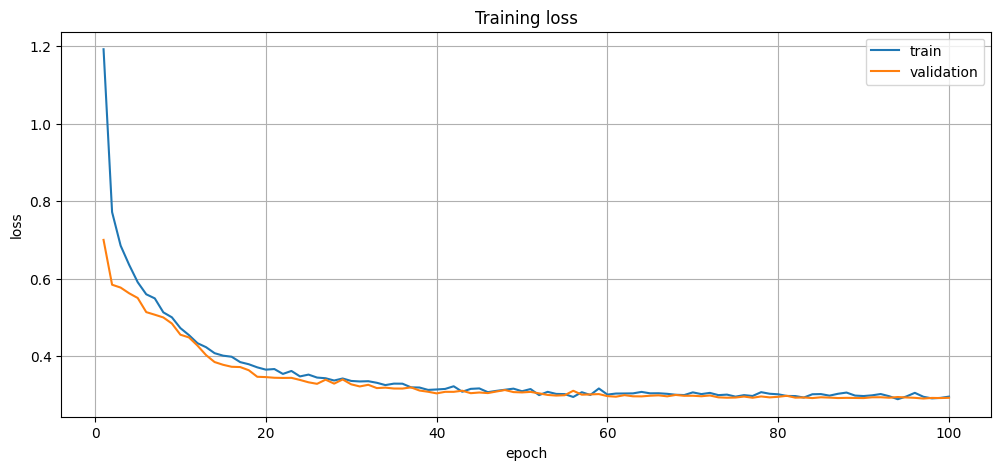

In [21]:
epochs = [
    row["epoch"]
    for row in history
]

train_losses = [
    row["train_loss"]
    for row in history
]

val_losses = [
    row["val_loss"]
    for row in history
]


plt.figure(
    figsize=(12, 5)
)

plt.plot(
    epochs,
    train_losses,
    label="train",
)

plt.plot(
    epochs,
    val_losses,
    label="validation",
)

plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training loss")
plt.grid(True)
plt.legend()
plt.show()


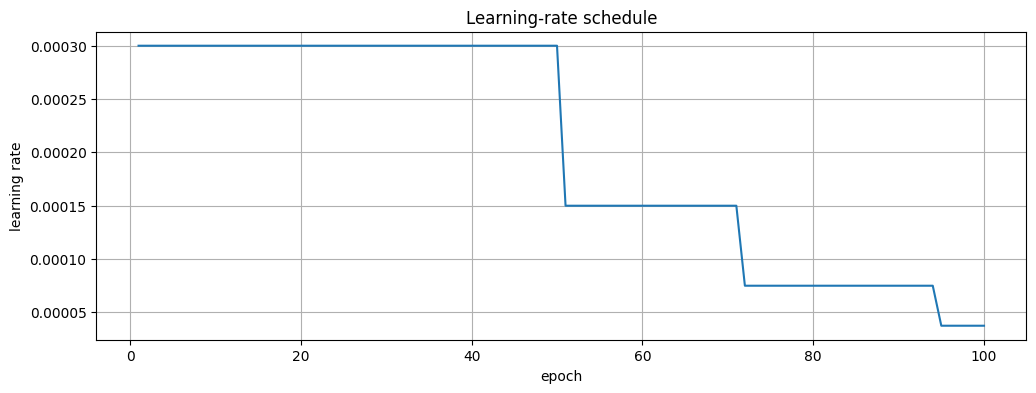

In [22]:
learning_rates = [
    row["learning_rate"]
    for row in history
]

plt.figure(
    figsize=(12, 4)
)

plt.plot(
    epochs,
    learning_rates,
)

plt.xlabel("epoch")
plt.ylabel("learning rate")
plt.title("Learning-rate schedule")
plt.grid(True)
plt.show()


## 14. Best-checkpoint test


In [23]:
best_checkpoint = load_training_checkpoint(
    BEST_CHECKPOINT_PATH,
    model=model,
    map_location=DEVICE,
    restore_rng_state=False,
)

test_augmentation_generator = make_augmentation_generator(
    TEST_AUGMENTATION_SEED
)

test_metrics, _ = run_epoch(
    test_loader,
    test_observability_cache,
    training=False,
    augmentation_generator=test_augmentation_generator,
)

print("Test metrics:")

for key, value in sorted(
    test_metrics.items()
):
    print(
        f"{key}: {value}"
    )


Test metrics:
epoch_time_s: 26.52818447999016
imu/event_accuracy: 1.0
imu/loss_change_event: 0.0036746340254867962
imu/loss_change_time: 0.0
imu/loss_rotation: 0.07296893426959265
imu/loss_time_offset: 0.12311552247520169
imu/loss_translation: 0.00015771951019605396
imu/observability_phi_mean: 0.2166733136120784
imu/observability_rho_mean: 6.307903850253058e-16
imu/observability_tau_mean: 0.7318929288861407
imu/rotation_error_deg: 6.2264004558623265
imu/time_offset_error_ms: 3.4017628647909315
imu/translation_error_cm: 5.9946663928816415
lidar/event_accuracy: 1.0
lidar/loss_change_event: 0.0042371613457159426
lidar/loss_change_time: 0.0
lidar/loss_rotation: 0.0718172362849692
lidar/loss_time_offset: 0.16102995532691394
lidar/loss_translation: 0.00013480590934031116
lidar/observability_phi_mean: 0.21667334435238517
lidar/observability_rho_mean: 1.2632511574833894e-27
lidar/observability_tau_mean: 0.5683702968903025
lidar/rotation_error_deg: 6.103331058322104
lidar/time_offset_error_ms: 

## 15. Calibration prediction visualization


In [24]:
##################################################
# Prediction visualization configuration
##################################################

VIS_SEQUENCE_NAME = "Urban38"

# Offset within this sequence's WindowSample list.
VIS_START_WINDOW = 0

# Number of consecutive windows to evaluate and plot.
VIS_NUM_WINDOWS = 80

# Evaluation batch size.
VIS_BATCH_SIZE = 16

# Separate deterministic augmentation realization for visualization.
VIS_AUGMENTATION_SEED = 56789


In [25]:
sequence_indices = [
    index
    for index in range(len(test_dataset))
    if test_dataset.sequence_name_for_window(index) == VIS_SEQUENCE_NAME
]

if not sequence_indices:
    raise ValueError(
        f"Sequence {VIS_SEQUENCE_NAME!r} is not present in test_dataset."
    )

selected_indices = sequence_indices[
    VIS_START_WINDOW : VIS_START_WINDOW + VIS_NUM_WINDOWS
]

if not selected_indices:
    raise ValueError(
        "Selected visualization window range is empty."
    )

print("Sequence:", VIS_SEQUENCE_NAME)
print("Selected windows:", len(selected_indices))
print(
    "Dataset indices:",
    selected_indices[0],
    "...",
    selected_indices[-1],
)


Sequence: Urban38
Selected windows: 80
Dataset indices: 0 ... 79


In [26]:
def collect_calibration_predictions(dataset, observability_cache, indices, *, batch_size, augmentation_seed):
    """Run selected windows with cached observability and collect calibration corrections."""

    model.eval()

    augmentation_generator = make_augmentation_generator(
        augmentation_seed
    )

    collected = {
        calibration_key: {
            "reference_delta_xi": [],
            "predicted_delta_xi": [],
            "reference_delta_tau": [],
            "predicted_delta_tau": [],
            "event_label": [],
            "event_probability": [],
            "reference_change_time": [],
            "predicted_change_time": [],
            "observability": [],
        }
        for calibration_key in model_config.head_keys
    }

    with torch.no_grad():
        for start in range(
            0,
            len(indices),
            batch_size,
        ):
            batch_indices = indices[
                start : start + batch_size
            ]

            base_window = collate_windows(
                [
                    dataset[index]
                    for index in batch_indices
                ]
            )

            if base_window.dataset_indices is None:
                raise ValueError(
                    "Visualization batches require dataset_indices."
                )

            observability = cached_observability_for_indices(
                observability_cache,
                base_window.dataset_indices,
                device=DEVICE,
                dtype=MODEL_DTYPE,
            )

            base_window = window_batch_to(
                base_window,
                DEVICE,
                dtype=MODEL_DTYPE,
            )

            augmentation_result = augmentation_pipeline(
                base_window,
                generator=augmentation_generator,
            )

            augmented_window = augmentation_result.augmented_window

            step_result = forward_cached_calibration_model(
                augmented_window,
                observability,
            )

            for calibration_key, prediction in step_result.model_output.predictions.items():
                target = augmented_window.targets[
                    calibration_key
                ]

                current_state = augmented_window.current_calibration[
                    calibration_key
                ]

                reference_delta_transform = (
                    target.next_transform
                    @ torch.linalg.inv(
                        current_state.transform
                    )
                )

                reference_delta_xi = se3_log(
                    reference_delta_transform
                )

                reference_delta_tau = (
                    target.next_time_offset
                    - current_state.time_offset
                )

                collected[calibration_key]["reference_delta_xi"].append(
                    reference_delta_xi.cpu()
                )

                collected[calibration_key]["predicted_delta_xi"].append(
                    prediction.delta_xi.cpu()
                )

                collected[calibration_key]["reference_delta_tau"].append(
                    reference_delta_tau.cpu()
                )

                collected[calibration_key]["predicted_delta_tau"].append(
                    prediction.delta_tau.cpu()
                )

                collected[calibration_key]["event_label"].append(
                    target.change_label.cpu()
                )

                collected[calibration_key]["event_probability"].append(
                    torch.sigmoid(
                        prediction.change_event_logit
                    ).cpu()
                )

                collected[calibration_key]["reference_change_time"].append(
                    target.change_time.cpu()
                )

                collected[calibration_key]["predicted_change_time"].append(
                    prediction.change_time.cpu()
                )

                collected[calibration_key]["observability"].append(
                    observability.calibration_features[
                        calibration_key
                    ].detach().cpu()
                )

    for calibration_key in collected:
        for field_name in collected[calibration_key]:
            collected[calibration_key][field_name] = torch.cat(
                collected[calibration_key][field_name],
                dim=0,
            ).numpy()

    return collected


visualization_results = collect_calibration_predictions(
    test_dataset,
    test_observability_cache,
    selected_indices,
    batch_size=VIS_BATCH_SIZE,
    augmentation_seed=VIS_AUGMENTATION_SEED,
)


In [27]:
CALIBRATION_COMPONENT_NAMES = (
    "phi_x",
    "phi_y",
    "phi_z",
    "rho_x",
    "rho_y",
    "rho_z",
)


def plot_calibration_corrections(results, calibration_key, window_stride_s):
    """Plot reference and predicted correction relative to the initial supplied calibration."""

    result = results[
        calibration_key
    ]

    reference_xi = result[
        "reference_delta_xi"
    ]

    predicted_xi = result[
        "predicted_delta_xi"
    ]

    reference_tau = result[
        "reference_delta_tau"
    ][:, 0]

    predicted_tau = result[
        "predicted_delta_tau"
    ][:, 0]

    times_s = (
        np.arange(
            len(reference_xi)
        )
        * window_stride_s
    )

    fig, axes = plt.subplots(
        7,
        1,
        figsize=(15, 16),
        sharex=True,
    )

    ##################################################
    # Rotation correction
    ##################################################

    for component_index in range(3):
        axes[component_index].plot(
            times_s,
            np.zeros_like(times_s),
            label="initial",
        )

        axes[component_index].plot(
            times_s,
            np.rad2deg(
                reference_xi[
                    :,
                    component_index,
                ]
            ),
            label="reference",
        )

        axes[component_index].plot(
            times_s,
            np.rad2deg(
                predicted_xi[
                    :,
                    component_index,
                ]
            ),
            label="predicted",
        )

        axes[component_index].set_ylabel(
            f"{CALIBRATION_COMPONENT_NAMES[component_index]} [deg]"
        )

        axes[component_index].grid(
            True
        )

        axes[component_index].legend()

    ##################################################
    # Translational SE3 tangent correction
    ##################################################

    for component_index in range(
        3,
        6,
    ):
        axes[component_index].plot(
            times_s,
            np.zeros_like(times_s),
            label="initial",
        )

        axes[component_index].plot(
            times_s,
            100.0
            * reference_xi[
                :,
                component_index,
            ],
            label="reference",
        )

        axes[component_index].plot(
            times_s,
            100.0
            * predicted_xi[
                :,
                component_index,
            ],
            label="predicted",
        )

        axes[component_index].set_ylabel(
            f"{CALIBRATION_COMPONENT_NAMES[component_index]} [cm]"
        )

        axes[component_index].grid(
            True
        )

        axes[component_index].legend()

    ##################################################
    # Temporal correction
    ##################################################

    axes[6].plot(
        times_s,
        np.zeros_like(times_s),
        label="initial",
    )

    axes[6].plot(
        times_s,
        1000.0 * reference_tau,
        label="reference",
    )

    axes[6].plot(
        times_s,
        1000.0 * predicted_tau,
        label="predicted",
    )

    axes[6].set_ylabel(
        "delta_tau [ms]"
    )

    axes[6].set_xlabel(
        "time across selected windows [s]"
    )

    axes[6].grid(
        True
    )

    axes[6].legend()

    fig.suptitle(
        f"{calibration_key}: calibration correction prediction"
    )

    fig.tight_layout()
    plt.show()


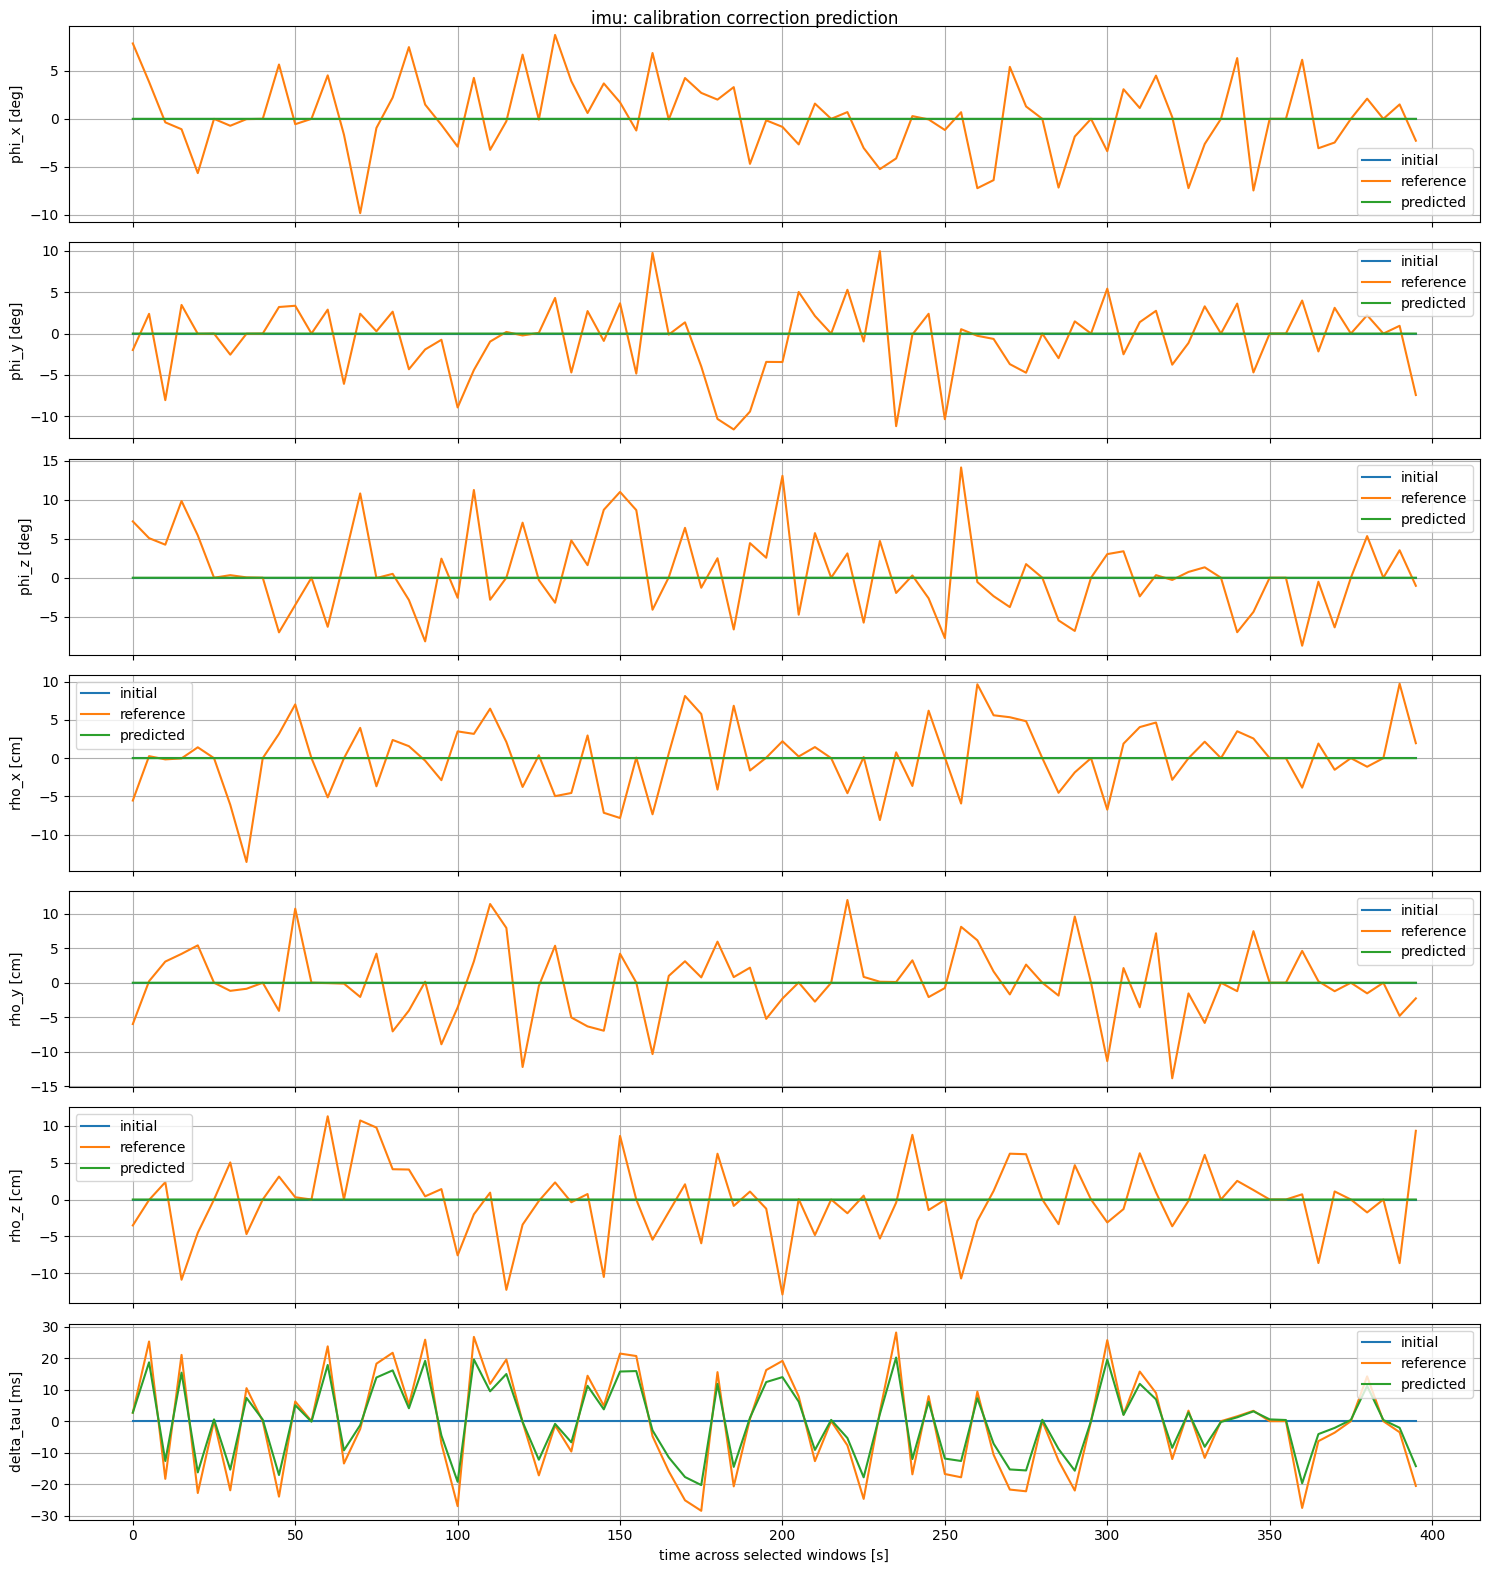

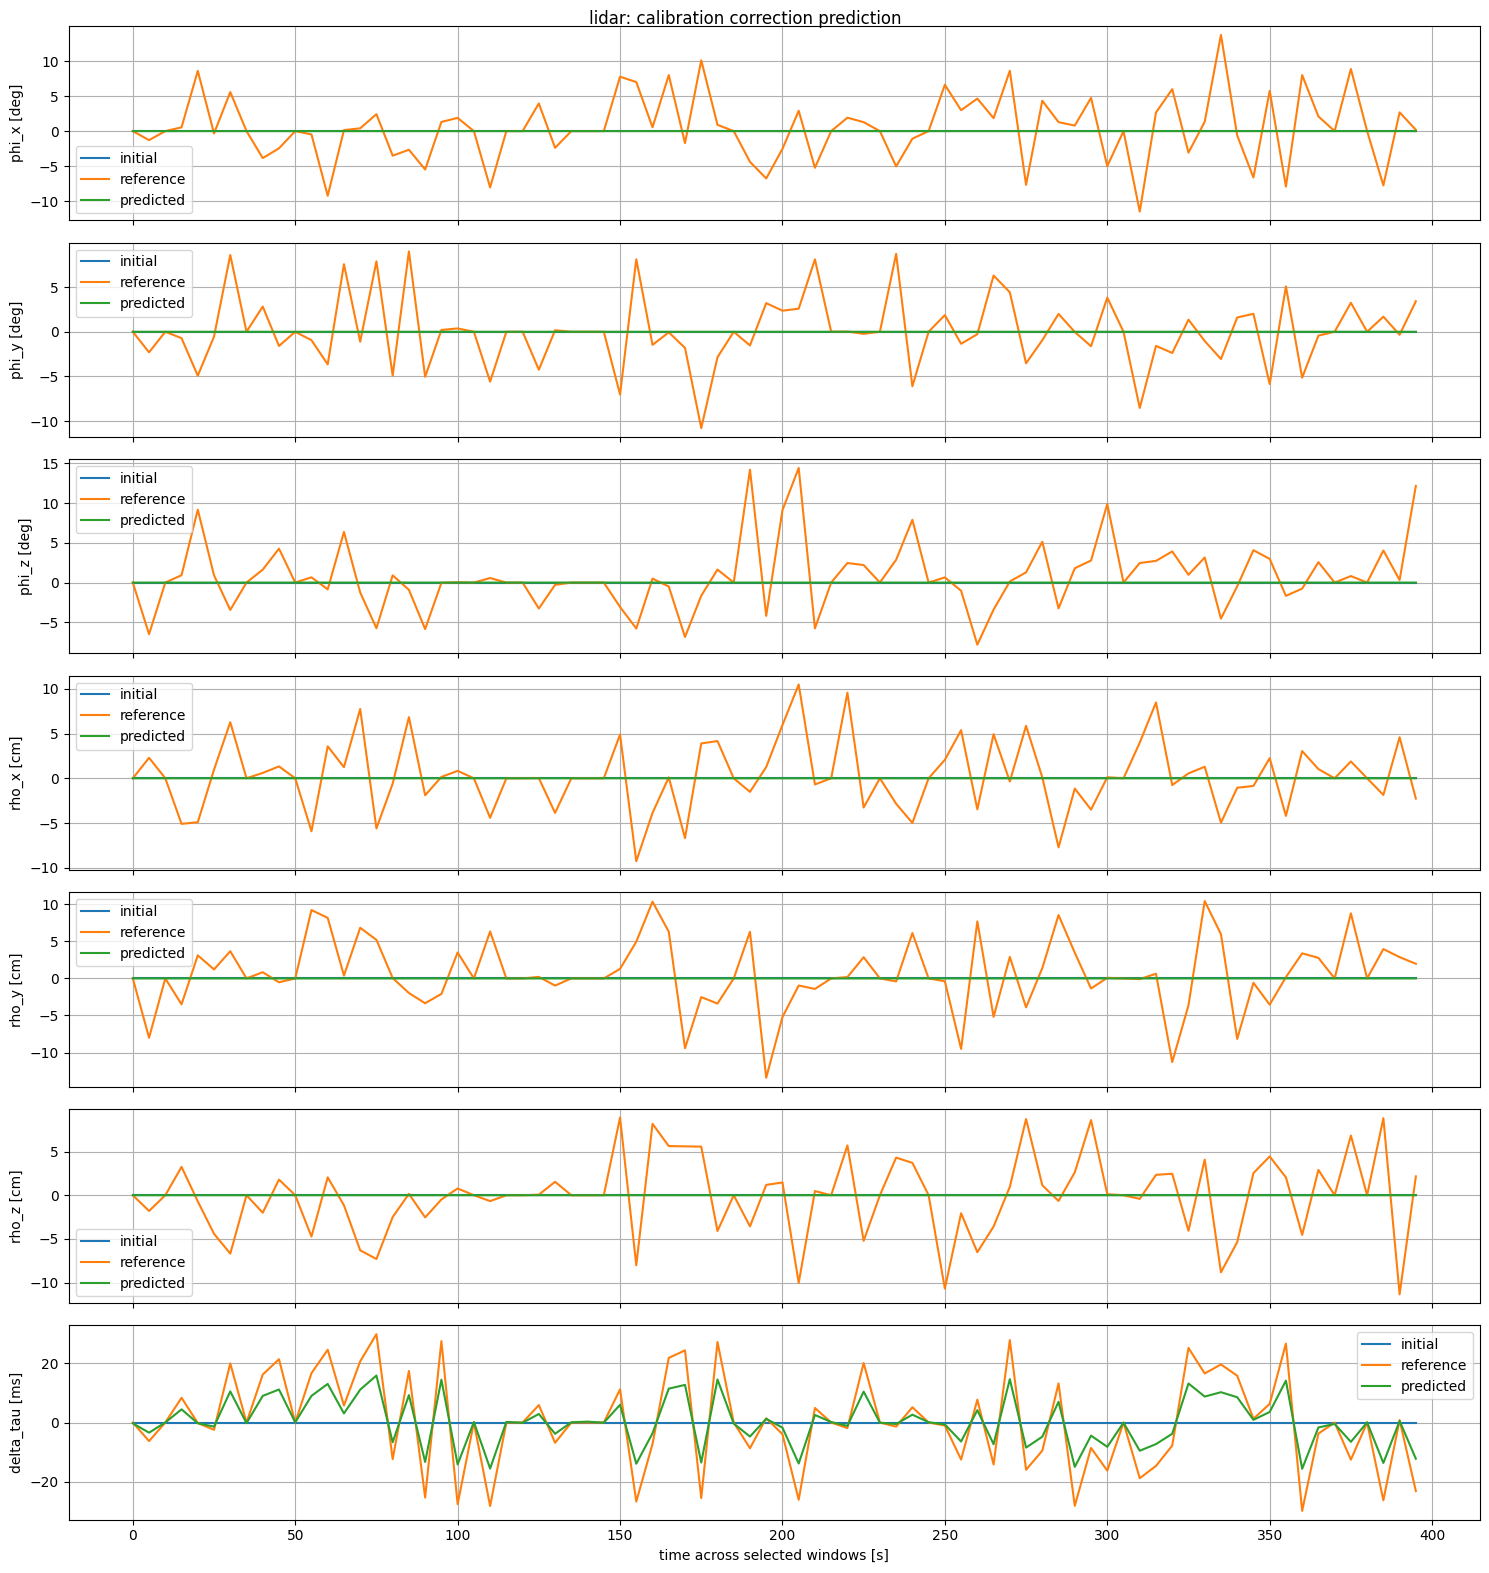

In [28]:
plot_calibration_corrections(
    visualization_results,
    "imu",
    WINDOW_STRIDE_S,
)

plot_calibration_corrections(
    visualization_results,
    "lidar",
    WINDOW_STRIDE_S,
)


In [29]:
def plot_correction_magnitudes(results, calibration_key, window_stride_s):
    """Plot scalar spatial and temporal correction magnitudes."""

    result = results[
        calibration_key
    ]

    reference_xi = result[
        "reference_delta_xi"
    ]

    predicted_xi = result[
        "predicted_delta_xi"
    ]

    reference_tau = result[
        "reference_delta_tau"
    ][:, 0]

    predicted_tau = result[
        "predicted_delta_tau"
    ][:, 0]

    times_s = (
        np.arange(
            len(reference_xi)
        )
        * window_stride_s
    )

    reference_rotation_deg = np.rad2deg(
        np.linalg.norm(
            reference_xi[:, :3],
            axis=1,
        )
    )

    predicted_rotation_deg = np.rad2deg(
        np.linalg.norm(
            predicted_xi[:, :3],
            axis=1,
        )
    )

    reference_translation_cm = (
        100.0
        * np.linalg.norm(
            reference_xi[:, 3:],
            axis=1,
        )
    )

    predicted_translation_cm = (
        100.0
        * np.linalg.norm(
            predicted_xi[:, 3:],
            axis=1,
        )
    )

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(15, 9),
        sharex=True,
    )

    axes[0].plot(
        times_s,
        reference_rotation_deg,
        label="reference",
    )

    axes[0].plot(
        times_s,
        predicted_rotation_deg,
        label="predicted",
    )

    axes[0].axhline(
        0.0,
        label="initial",
    )

    axes[0].set_ylabel(
        "rotation [deg]"
    )

    axes[0].grid(
        True
    )

    axes[0].legend()

    axes[1].plot(
        times_s,
        reference_translation_cm,
        label="reference",
    )

    axes[1].plot(
        times_s,
        predicted_translation_cm,
        label="predicted",
    )

    axes[1].axhline(
        0.0,
        label="initial",
    )

    axes[1].set_ylabel(
        "rho norm [cm]"
    )

    axes[1].grid(
        True
    )

    axes[1].legend()

    axes[2].plot(
        times_s,
        1000.0 * reference_tau,
        label="reference",
    )

    axes[2].plot(
        times_s,
        1000.0 * predicted_tau,
        label="predicted",
    )

    axes[2].axhline(
        0.0,
        label="initial",
    )

    axes[2].set_ylabel(
        "delta_tau [ms]"
    )

    axes[2].set_xlabel(
        "time across selected windows [s]"
    )

    axes[2].grid(
        True
    )

    axes[2].legend()

    fig.suptitle(
        f"{calibration_key}: correction magnitudes"
    )

    fig.tight_layout()
    plt.show()


## 16. Initial-vs-model error summary


In [30]:
def print_initial_vs_model_errors(results, calibration_key):
    """Compare the trained model against a zero-correction baseline."""

    result = results[
        calibration_key
    ]

    reference_xi = result[
        "reference_delta_xi"
    ]

    predicted_xi = result[
        "predicted_delta_xi"
    ]

    reference_tau = result[
        "reference_delta_tau"
    ][:, 0]

    predicted_tau = result[
        "predicted_delta_tau"
    ][:, 0]

    ##################################################
    # Initial calibration means predicted correction = 0
    ##################################################

    initial_rotation_error_deg = np.rad2deg(
        np.linalg.norm(
            reference_xi[:, :3],
            axis=1,
        )
    )

    model_rotation_error_deg = np.rad2deg(
        np.linalg.norm(
            predicted_xi[:, :3]
            - reference_xi[:, :3],
            axis=1,
        )
    )

    initial_translation_error_cm = (
        100.0
        * np.linalg.norm(
            reference_xi[:, 3:],
            axis=1,
        )
    )

    model_translation_error_cm = (
        100.0
        * np.linalg.norm(
            predicted_xi[:, 3:]
            - reference_xi[:, 3:],
            axis=1,
        )
    )

    initial_tau_error_ms = (
        1000.0
        * np.abs(
            reference_tau
        )
    )

    model_tau_error_ms = (
        1000.0
        * np.abs(
            predicted_tau
            - reference_tau
        )
    )

    print(calibration_key)
    print()

    print(
        f"rotation:    initial={initial_rotation_error_deg.mean():.3f} deg, "
        f"model={model_rotation_error_deg.mean():.3f} deg"
    )

    print(
        f"translation: initial={initial_translation_error_cm.mean():.3f} cm, "
        f"model={model_translation_error_cm.mean():.3f} cm"
    )

    print(
        f"time offset: initial={initial_tau_error_ms.mean():.3f} ms, "
        f"model={model_tau_error_ms.mean():.3f} ms"
    )


In [31]:
print_initial_vs_model_errors(
    visualization_results,
    "imu",
)

print()

print_initial_vs_model_errors(
    visualization_results,
    "lidar",
)


imu

rotation:    initial=6.349 deg, model=6.349 deg
translation: initial=6.712 cm, model=6.712 cm
time offset: initial=12.419 ms, model=3.438 ms

lidar

rotation:    initial=5.818 deg, model=5.818 deg
translation: initial=5.927 cm, model=5.928 cm
time offset: initial=11.775 ms, model=5.604 ms


## 17. Prediction-collapse diagnostics


In [32]:
def print_prediction_collapse_diagnostics(results, calibration_key):
    result = results[
        calibration_key
    ]

    reference_xi = result[
        "reference_delta_xi"
    ]

    predicted_xi = result[
        "predicted_delta_xi"
    ]

    names = (
        "phi_x",
        "phi_y",
        "phi_z",
        "rho_x",
        "rho_y",
        "rho_z",
    )

    print(
        calibration_key
    )

    print()

    for index, name in enumerate(
        names
    ):
        target = reference_xi[
            :,
            index,
        ]

        prediction = predicted_xi[
            :,
            index,
        ]

        if np.std(target) > 0.0 and np.std(prediction) > 0.0:
            correlation = np.corrcoef(
                target,
                prediction,
            )[0, 1]
        else:
            correlation = np.nan

        print(
            f"{name:5s}  "
            f"target std={np.std(target):.5f}  "
            f"pred std={np.std(prediction):.5f}  "
            f"corr={correlation:+.3f}"
        )


print_prediction_collapse_diagnostics(
    visualization_results,
    "imu",
)

print()

print_prediction_collapse_diagnostics(
    visualization_results,
    "lidar",
)


imu

phi_x  target std=0.06560  pred std=0.00000  corr=+0.240
phi_y  target std=0.07448  pred std=0.00000  corr=+0.131
phi_z  target std=0.08807  pred std=0.00000  corr=-0.021
rho_x  target std=0.04291  pred std=0.00001  corr=+0.121
rho_y  target std=0.05039  pred std=0.00000  corr=-0.000
rho_z  target std=0.05006  pred std=0.00000  corr=-0.045

lidar

phi_x  target std=0.08205  pred std=0.00000  corr=+0.079
phi_y  target std=0.06723  pred std=0.00000  corr=+0.133
phi_z  target std=0.07386  pred std=0.00000  corr=+0.246
rho_x  target std=0.03815  pred std=0.00000  corr=-0.054
rho_y  target std=0.04647  pred std=0.00000  corr=-0.069
rho_z  target std=0.04403  pred std=0.00000  corr=+0.147


## 18. Cached observability over the selected sequence


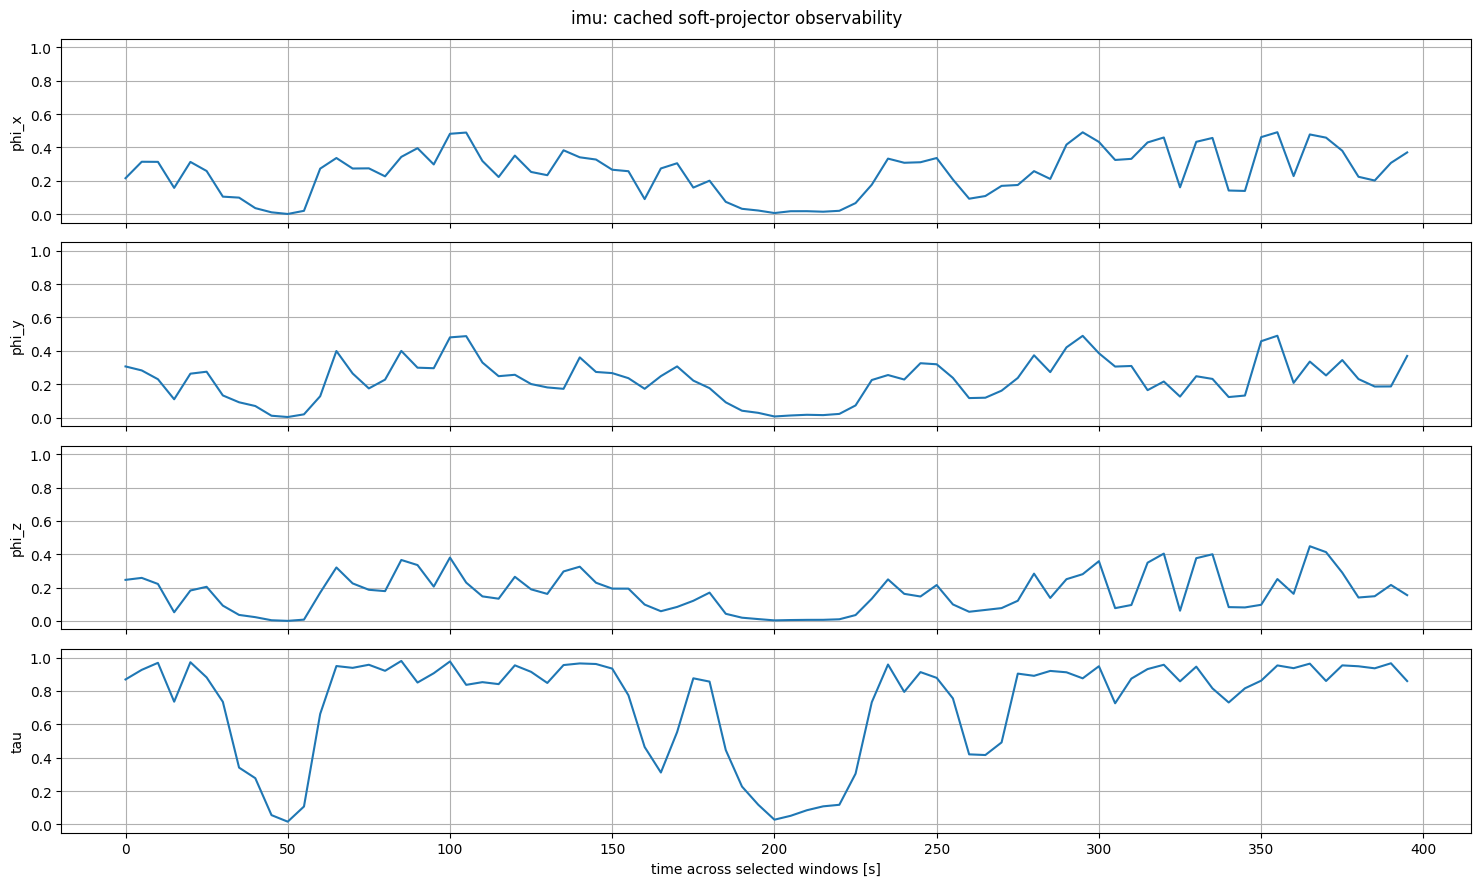

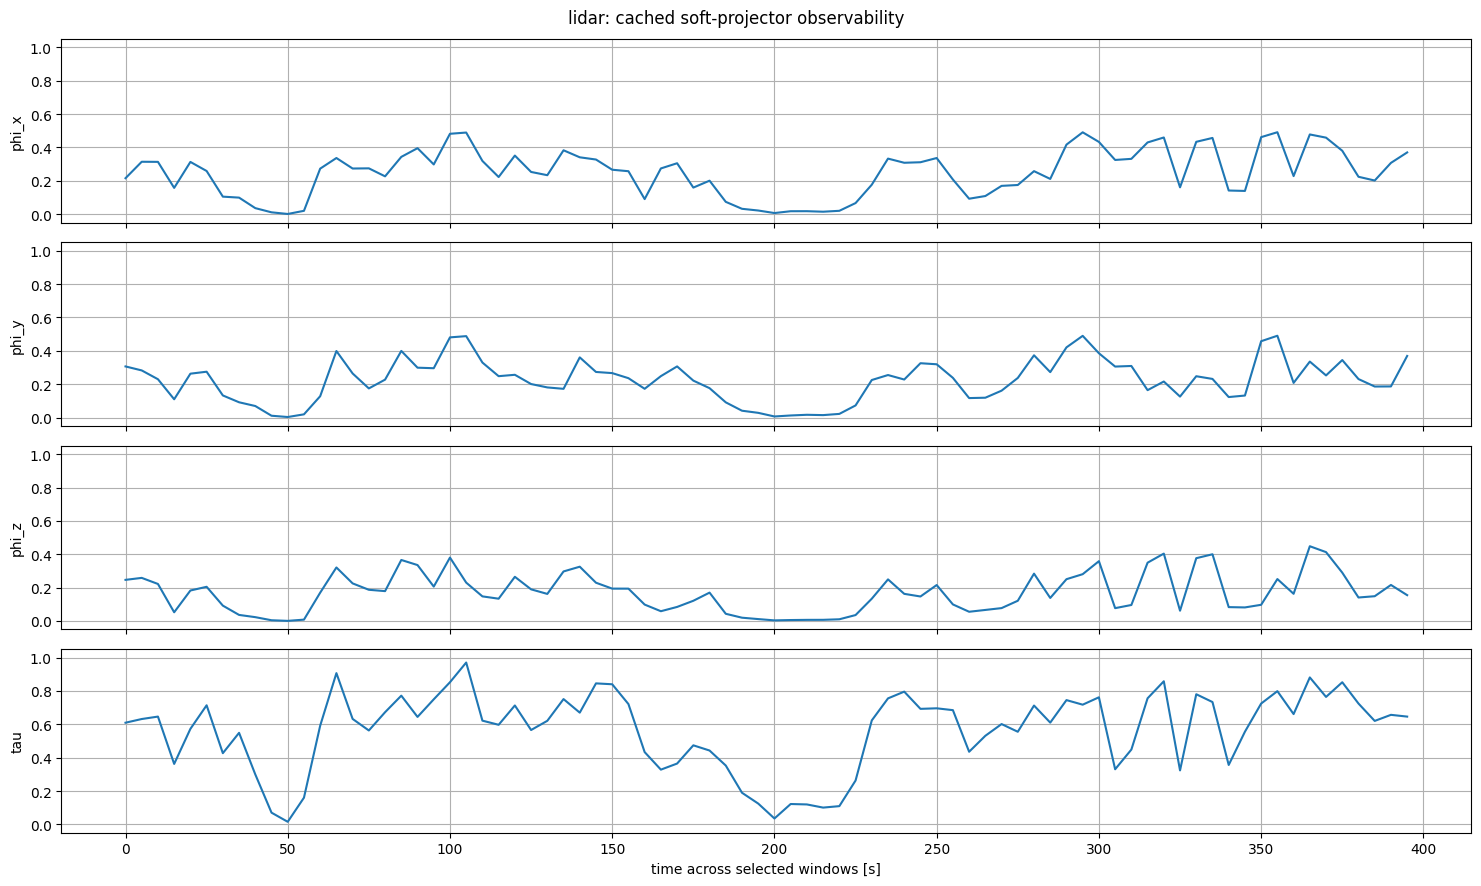

In [33]:
def plot_cached_observability(results, calibration_key, window_stride_s):
    values = results[
        calibration_key
    ][
        "observability"
    ]

    times_s = np.arange(
        len(values)
    ) * window_stride_s

    plotted_components = (
        ("phi_x", 0),
        ("phi_y", 1),
        ("phi_z", 2),
        ("tau", 6),
    )

    fig, axes = plt.subplots(
        len(plotted_components),
        1,
        figsize=(15, 9),
        sharex=True,
    )

    for axis, (component_name, component_index) in zip(
        axes,
        plotted_components,
    ):
        axis.plot(
            times_s,
            values[:, component_index],
        )

        axis.set_ylabel(
            component_name
        )

        axis.set_ylim(
            -0.05,
            1.05,
        )

        axis.grid(
            True
        )

    axes[-1].set_xlabel(
        "time across selected windows [s]"
    )

    fig.suptitle(
        f"{calibration_key}: cached soft-projector observability"
    )

    fig.tight_layout()
    plt.show()


plot_cached_observability(
    visualization_results,
    "imu",
    WINDOW_STRIDE_S,
)

plot_cached_observability(
    visualization_results,
    "lidar",
    WINDOW_STRIDE_S,
)


## 19. Interpretation

This is the oracle/cached-observability calibration experiment.

The most important comparison is against a calibration predictor trained **without observability** while keeping the dataset split, calibration architecture, augmentation distribution, optimizer, and training budget the same.

If the cached-observability model clearly improves calibration prediction, the next controlled experiment is to replace these numerical cached scores with the frozen learned observability predictor 008 while keeping the rest of this notebook unchanged.
